# 17 — RAID adversarial detector comparison

This notebook is **standalone**. It assumes no variables or cells from any other notebook are in memory.

It uses only:
1. the saved machine SL6 result:
   `results/raid_attacks_machine_sl6_qwen06b.parquet`;
2. the cached public RAID train CSV:
   `~/.cache/raid/train.csv`;
3. public WaveDetect weights, downloaded automatically if not already cached.

It compares five detectors/features:

\[
L_{256},\qquad
SL6=(L_8,L_{16},L_{32},L_{64},L_{128},L_{256}),
\]

\[
W,\qquad
W+L_{256},\qquad
W+SL6.
\]

The detector is always trained/calibrated on **clean machine text versus matched human text**. Adversarial variants are used **only at evaluation time**. Thus attacks do not leak into detector training.

For comparability with RAID Table 6, the primary metric is **accuracy at a threshold calibrated to 5% FPR on training human text**. We also report TPR@5%FPR, realized held-out FPR, and AUROC.


## 1. Setup and saved inputs


In [1]:
from pathlib import Path
import sys, gc, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd

DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
EXTERNAL = DATA / "external"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
EXTERNAL.mkdir(parents=True, exist_ok=True)

RAID_CSV = Path.home() / ".cache" / "raid" / "train.csv"
MACHINE_SL6_PATH = RESULTS / "raid_attacks_machine_sl6_qwen06b.parquet"

assert RAID_CSV.exists(), (
    f"Missing cached RAID train split: {RAID_CSV}\n"
    "Download it once with raid.utils.load_data(split='train'), then restart "
    "the kernel and use this notebook."
)
assert MACHINE_SL6_PATH.exists(), (
    f"Missing saved machine SL6 result: {MACHINE_SL6_PATH}"
)

machine = pd.read_parquet(MACHINE_SL6_PATH)

K_VALUES = [8,16,32,64,128,256]
SL6_COLS = [f"L_{k}" for k in K_VALUES]

needed = {
    "id","parent_id","attack","source_id","model",
    *SL6_COLS
}
missing = needed - set(machine.columns)
assert not missing, f"Machine SL6 cache missing: {sorted(missing)}"

print("ROOT:", ROOT)
print("RAID CSV GB:", RAID_CSV.stat().st_size/1e9)
print("machine rows:", len(machine))
print("machine attacks:", sorted(machine["attack"].astype(str).unique()))
print("machine sources:", machine["source_id"].nunique())


ROOT: ..
RAID CSV GB: 11.779491051
machine rows: 660
machine attacks: ['alternative_spelling', 'article_deletion', 'homoglyph', 'insert_paragraphs', 'none', 'number', 'paraphrase', 'perplexity_misspelling', 'synonym', 'upper_lower', 'whitespace', 'zero_width_space']
machine sources: 55


## 2. Reconstruct only the raw texts needed for this experiment

The machine cache stores IDs and features, not text. We stream the 11.8 GB RAID CSV and retrieve only:

- the machine rows already present in the saved SL6 cache;
- the matched human source rows whose `id == source_id`.

No full RAID dataframe is loaded into RAM.


In [2]:
RAW_CACHE = RESULTS / "raid_detector_comparison_raw_rows.parquet"

if RAW_CACHE.exists():
    raw = pd.read_parquet(RAW_CACHE)
    print("loaded raw-row cache:", raw.shape)
else:
    machine_ids = set(machine["id"].astype(str))
    human_ids = set(machine["source_id"].astype(str))
    wanted_ids = machine_ids | human_ids

    usecols = [
        "id","adv_source_id","source_id","model","decoding",
        "repetition_penalty","attack","domain","generation"
    ]

    pieces = []

    for j, chunk in enumerate(pd.read_csv(
        RAID_CSV,
        usecols=usecols,
        chunksize=100_000,
    )):
        keep = chunk[chunk["id"].astype(str).isin(wanted_ids)]
        if len(keep):
            pieces.append(keep.copy())

        if j % 20 == 0:
            found = sum(len(x) for x in pieces)
            print(f"chunks {j:4d} | rows found {found}")

    raw = pd.concat(pieces, ignore_index=True).drop_duplicates("id")
    raw.to_parquet(RAW_CACHE, index=False)

print("raw rows:", len(raw))

machine_text = raw[raw["id"].astype(str).isin(set(machine["id"].astype(str)))].copy()

human_ids = set(machine["source_id"].astype(str))
human_text = raw[
    raw["id"].astype(str).isin(human_ids)
    & raw["model"].astype(str).eq("human")
    & raw["attack"].astype(str).eq("none")
].copy()

print("machine texts:", len(machine_text), "/", len(machine))
print("matched human texts:", len(human_text), "/", len(human_ids))

assert len(machine_text) == len(machine), "Some machine texts were not recovered."
assert human_text["id"].nunique() == len(human_ids), "Some matched human sources were not recovered."


chunks    0 | rows found 0
chunks   20 | rows found 584
chunks   40 | rows found 715
raw rows: 715
machine texts: 660 / 660
matched human texts: 55 / 55


## 3. Score the matched human negatives with the same Qwen SL6 procedure

Machine SL6 values are already saved. Only the matched human negatives need Qwen scoring here.

The scoring rule matches the attack experiment: up to 384 scorer tokens, at least 257 tokens required, and up to eight deterministic target positions from token 256 to the end of the available prefix.


In [3]:
from transformers import AutoTokenizer, AutoModelForCausalLM

HUMAN_SL6_PATH = RESULTS / "raid_detector_comparison_human_sl6_qwen06b.parquet"
QWEN_ID = "Qwen/Qwen3-0.6B-Base"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

if HUMAN_SL6_PATH.exists():
    human_sl6 = pd.read_parquet(HUMAN_SL6_PATH)
    print("loaded human SL6 cache:", human_sl6.shape)
else:
    tokenizer = AutoTokenizer.from_pretrained(QWEN_ID)
    qwen = AutoModelForCausalLM.from_pretrained(
        QWEN_ID,
        torch_dtype=DTYPE,
    )
    qwen.eval().to(DEVICE)

    @torch.inference_mode()
    def nll_at_context(ids, target, k):
        start = max(0, target-k)
        x = torch.tensor(
            ids[start:target+1],
            dtype=torch.long,
            device=DEVICE,
        )[None,:]

        logits = qwen(input_ids=x).logits
        pred = logits[0,-2].float()
        y = torch.tensor([ids[target]], dtype=torch.long, device=DEVICE)

        return float(
            torch.nn.functional.cross_entropy(
                pred[None,:], y
            ).item()
        )

    def score_qwen(text):
        ids = tokenizer(
            str(text),
            add_special_tokens=False,
            truncation=True,
            max_length=384,
        )["input_ids"]

        if len(ids) <= 256:
            return None

        last = len(ids)-1
        n_targets = min(8, last-255)
        targets = np.unique(
            np.linspace(256, last, n_targets).round().astype(int)
        )

        out = {
            "n_tokens_scored":len(ids),
            "n_targets":len(targets),
        }

        for k in K_VALUES:
            out[f"L_{k}"] = float(np.mean([
                nll_at_context(ids, int(t), k)
                for t in targets
            ]))
        return out

    rows = []
    t0 = time.time()

    for i,r in enumerate(human_text.itertuples(index=False), start=1):
        s = score_qwen(r.generation)

        row = {
            "id":r.id,
            "source_id":r.id,
            "model":"human",
        }

        if s is None:
            row.update({
                "n_tokens_scored":np.nan,
                "n_targets":np.nan,
                **{f"L_{k}":np.nan for k in K_VALUES},
            })
        else:
            row.update(s)

        rows.append(row)

        if i % 10 == 0:
            pd.DataFrame(rows).to_parquet(HUMAN_SL6_PATH, index=False)
            print(f"{i}/{len(human_text)} human Qwen scored | {(time.time()-t0)/60:.1f} min")

    human_sl6 = pd.DataFrame(rows)
    human_sl6.to_parquet(HUMAN_SL6_PATH, index=False)

    del qwen
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(
    "eligible human SL6:",
    human_sl6[SL6_COLS].notna().all(axis=1).sum(),
    "/",
    len(human_sl6),
)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3208.78it/s]


10/55 human Qwen scored | 0.2 min
20/55 human Qwen scored | 0.3 min
30/55 human Qwen scored | 0.5 min
40/55 human Qwen scored | 0.6 min
50/55 human Qwen scored | 0.8 min
eligible human SL6: 53 / 55


## 4. Load the public WaveDetect model and score all required rows

This notebook reproduces the public WaveDetect inference path directly.

Public model:
`KaitongQin/WaveDetect`

Pinned public revision:
`d38df62`

WaveDetect is scored one document at a time, as in the released predictor. Results are checkpointed and resumable.


In [4]:
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm

HF_REPO = "KaitongQin/WaveDetect"
HF_REVISION = "d38df62"
WAVE_MODEL_DIR = EXTERNAL / "wavedetect_hf"
WAVE_SCORE_PATH = RESULTS / "raid_detector_comparison_wavedetect.parquet"

if not (WAVE_MODEL_DIR / "wavedetect_hf.py").exists():
    print("Downloading public WaveDetect snapshot...")
    snapshot_download(
        repo_id=HF_REPO,
        revision=HF_REVISION,
        local_dir=str(WAVE_MODEL_DIR),
    )

sys.path.insert(0, str(WAVE_MODEL_DIR))

from wavedetect_hf import WaveDetectPredictor

wave_predictor = WaveDetectPredictor(
    model_dir=WAVE_MODEL_DIR,
    device=DEVICE,
    max_length=1024,
)

all_text = pd.concat([
    machine_text[["id","generation"]],
    human_text[["id","generation"]],
], ignore_index=True).drop_duplicates("id")

if WAVE_SCORE_PATH.exists():
    wave_scores = pd.read_parquet(WAVE_SCORE_PATH)
else:
    wave_scores = pd.DataFrame(columns=["id","wave_ai_score","wave_error"])

done = set(wave_scores["id"].astype(str))
pending = all_text[
    ~all_text["id"].astype(str).isin(done)
].copy()

print("WaveDetect already scored:", len(done))
print("WaveDetect remaining:", len(pending))

records = wave_scores.to_dict("records")
SAVE_EVERY = 25

for i,row in enumerate(
    tqdm(pending.itertuples(index=False), total=len(pending), desc="WaveDetect"),
    start=1,
):
    try:
        pred = wave_predictor.predict(str(row.generation))
        score = float(pred["ai_score"])
        err = None
    except Exception as exc:
        score = np.nan
        err = f"{type(exc).__name__}: {exc}"

    records.append({
        "id":row.id,
        "wave_ai_score":score,
        "wave_error":err,
    })

    if i % SAVE_EVERY == 0:
        pd.DataFrame(records).drop_duplicates(
            "id", keep="last"
        ).to_parquet(WAVE_SCORE_PATH, index=False)

wave_scores = pd.DataFrame(records).drop_duplicates("id", keep="last")
wave_scores.to_parquet(WAVE_SCORE_PATH, index=False)

print("WaveDetect rows:", len(wave_scores))
print("successful:", wave_scores["wave_ai_score"].notna().sum())
print("failed:", wave_scores["wave_ai_score"].isna().sum())

del wave_predictor
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


WaveDetect already scored: 0
WaveDetect remaining: 715


WaveDetect: 100%|█████████████████████████████████████████████████████████████████████████████████████| 715/715 [00:25<00:00, 27.86it/s]


WaveDetect rows: 715
successful: 715
failed: 0


## 5. Assemble matched human/machine feature tables

WaveDetect probability is clipped and converted to its logit

\[
W=\log\frac{p}{1-p}.
\]

The machine table contains clean plus all attacks. Human negatives are the matched source texts.


In [5]:
EPS = 1e-6

wave = wave_scores[["id","wave_ai_score"]].copy()
p = wave["wave_ai_score"].clip(EPS,1-EPS)
wave["W"] = np.log(p/(1-p))

machine_f = (
    machine
    .merge(wave[["id","W"]], on="id", how="left", validate="one_to_one")
)

human_f = (
    human_sl6
    .merge(wave[["id","W"]], on="id", how="left", validate="one_to_one")
)

# prompt/source key shared by machine output and matched human source.
machine_f["prompt_id"] = machine_f["source_id"].astype(str)
human_f["prompt_id"] = human_f["id"].astype(str)

print("machine W available:", machine_f["W"].notna().sum(), "/", len(machine_f))
print("human W available:", human_f["W"].notna().sum(), "/", len(human_f))

display(machine_f.head())
display(human_f.head())


machine W available: 660 / 660
human W available: 55 / 55


,id,parent_id,variant,attack,adv_source_id,source_id,model,domain,n_tokens_scored,n_targets,L_8,L_16,L_32,L_64,L_128,L_256,W,prompt_id
0,2b5700cb-abc0-4750-83c5-c2eaa422526c,2b5700cb-abc0-4750-83c5-c2eaa422526c,none,none,2b5700cb-abc0-4750-83c5-c2eaa422526c,561b894b-54b4-4fae-a893-722c9f9732b4,mistral,news,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.520958,561b894b-54b4-4fae-a893-722c9f9732b4
1,c50ab047-e404-4e7b-b429-c7eb094ef8d4,c50ab047-e404-4e7b-b429-c7eb094ef8d4,none,none,c50ab047-e404-4e7b-b429-c7eb094ef8d4,00a84a82-e52d-4260-ae8b-4b6dea908df7,mistral,news,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.561929,00a84a82-e52d-4260-ae8b-4b6dea908df7
2,79c9e9df-e45c-4736-85b0-ad08eac0c340,79c9e9df-e45c-4736-85b0-ad08eac0c340,none,none,79c9e9df-e45c-4736-85b0-ad08eac0c340,00a6a505-c08f-4a51-893f-7f5b248f5337,llama-chat,news,384.0,8.0,3.493028,2.711290,2.798180,2.205269,2.071185,1.871070,9.514206,00a6a505-c08f-4a51-893f-7f5b248f5337
3,8f703b7e-29fb-4016-ae78-4ece9ec0bf1b,8f703b7e-29fb-4016-ae78-4ece9ec0bf1b,none,none,8f703b7e-29fb-4016-ae78-4ece9ec0bf1b,5b43d364-3cb9-4eab-b39b-88490ea891e4,mpt,news,384.0,8.0,6.420372,5.400459,5.228121,4.920901,4.638794,4.733540,3.789941,5b43d364-3cb9-4eab-b39b-88490ea891e4
4,6b7ced55-c54a-4a39-b9f6-f6af50254d69,6b7ced55-c54a-4a39-b9f6-f6af50254d69,none,none,6b7ced55-c54a-4a39-b9f6-f6af50254d69,cb401bb1-65f9-4969-8ed3-ee41c9a9f67f,mpt,news,296.0,8.0,6.905655,5.940151,5.232169,4.909424,4.815932,4.778019,4.493070,cb401bb1-65f9-4969-8ed3-ee41c9a9f67f


,id,source_id,model,n_tokens_scored,n_targets,L_8,L_16,L_32,L_64,L_128,L_256,W,prompt_id
0,49433823-ef58-45fc-99e2-5a58fb93ba66,49433823-ef58-45fc-99e2-5a58fb93ba66,human,384.0,8.0,4.191660,3.074180,3.051113,2.782713,2.734764,2.723744,-3.950981,49433823-ef58-45fc-99e2-5a58fb93ba66
1,f7df86c7-daae-456a-b5dd-1601c1007c75,f7df86c7-daae-456a-b5dd-1601c1007c75,human,384.0,8.0,4.161691,3.507859,3.254018,3.360813,3.278529,3.149106,-4.502113,f7df86c7-daae-456a-b5dd-1601c1007c75
2,00a41757-bcfa-468b-a335-4be5569b2c98,00a41757-bcfa-468b-a335-4be5569b2c98,human,368.0,8.0,4.560717,3.729867,3.507807,2.448111,2.274284,1.778557,-3.699534,00a41757-bcfa-468b-a335-4be5569b2c98
3,eeffec07-a36a-44d1-804b-ec3e40358204,eeffec07-a36a-44d1-804b-ec3e40358204,human,384.0,8.0,4.588010,3.844620,2.827916,2.584138,2.708703,1.900804,-3.075246,eeffec07-a36a-44d1-804b-ec3e40358204
4,bf1ac829-90bf-497b-8db0-ef563160f874,bf1ac829-90bf-497b-8db0-ef563160f874,human,384.0,8.0,4.557543,3.817760,4.060502,2.887175,2.781398,2.606366,-3.720925,bf1ac829-90bf-497b-8db0-ef563160f874


## 6. Evaluation protocol: train clean, test adversarial

For each of 20 deterministic source-level splits:

1. select source IDs eligible for the requested attack and all five methods;
2. split source IDs 80/20;
3. train learned detectors **only on clean machine outputs versus matched human texts** from training sources;
4. choose regularization by inner source-level clean-data CV;
5. calibrate the detector threshold on **training-human scores** to target 5% FPR;
6. evaluate the same frozen detector/threshold on:
   - held-out clean machine text + held-out humans (`none`);
   - held-out attacked machine text + the same held-out humans.

WaveDetect itself is not retrained; only its 5%-FPR threshold is calibrated from training-human WaveDetect scores.

This is the key robustness design: attacks are never seen during training or hyperparameter selection.


In [6]:
L256 = ["L_256"]
SL6 = SL6_COLS

FEATURE_SETS = {
    "L256": L256,
    "SL6": SL6,
    "W+L256": ["W"] + L256,
    "W+SL6": ["W"] + SL6,
}

C_GRID = [0.01,0.1,1.0,10.0]

def make_clf(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            C=C,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
        )),
    ])

def build_clean_train(prompt_ids, cols):
    m = machine_f[
        machine_f["attack"].astype(str).eq("none")
        & machine_f["prompt_id"].isin(prompt_ids)
    ][["prompt_id"] + cols].copy()
    m["label"] = 1

    h = human_f[
        human_f["prompt_id"].isin(prompt_ids)
    ][["prompt_id"] + cols].copy()
    h["label"] = 0

    return pd.concat([m,h], ignore_index=True).dropna(subset=cols)

def choose_C(clean_train, cols, seed):
    # Small deterministic source-level inner CV on clean data only.
    groups = np.array(sorted(clean_train["prompt_id"].unique()))
    if len(groups) < 5:
        return 0.1

    rng = np.random.default_rng(seed + 17000)
    groups = rng.permutation(groups)
    folds = np.array_split(groups, min(5,len(groups)))

    scores = []

    for C in C_GRID:
        aucs = []
        for valid_groups in folds:
            vg = set(valid_groups)
            tr = clean_train[~clean_train["prompt_id"].isin(vg)]
            va = clean_train[clean_train["prompt_id"].isin(vg)]

            if tr["label"].nunique()<2 or va["label"].nunique()<2:
                continue

            clf = make_clf(C)
            clf.fit(tr[cols],tr["label"])
            pr = clf.predict_proba(va[cols])[:,1]
            aucs.append(roc_auc_score(va["label"],pr))

        scores.append((np.mean(aucs) if aucs else -np.inf,C))

    scores.sort(key=lambda x:(-x[0],x[1]))
    return scores[0][1]

def threshold_at_fpr5(human_scores):
    # Higher score = more AI-like. 95th percentile targets 5% train-human FPR.
    human_scores = np.asarray(human_scores,float)
    return float(np.quantile(human_scores,0.95,method="higher"))

def metrics_at_threshold(y, score, threshold):
    y = np.asarray(y,int)
    score = np.asarray(score,float)
    pred = (score >= threshold).astype(int)

    human = y==0
    machine_mask = y==1

    return {
        "accuracy_at_fpr5":accuracy_score(y,pred),
        "balanced_accuracy_at_fpr5":balanced_accuracy_score(y,pred),
        "tpr_at_fpr5":float(pred[machine_mask].mean()),
        "realized_fpr":float(pred[human].mean()),
        "f1_at_fpr5":f1_score(y,pred,zero_division=0),
        "auroc":roc_auc_score(y,score),
    }


## 7. Run the 20 split clean→attack evaluation

To make method comparisons fair, each attack uses a **common-support source set** on which:

- matched human SL6 + WaveDetect exist;
- clean machine SL6 + WaveDetect exist;
- the attacked machine SL6 + WaveDetect exist.

Thus `W`, `L256`, `SL6`, `W+L256`, and `W+SL6` are compared on identical texts for each condition.


In [7]:
ATTACKS = sorted(
    x for x in machine_f["attack"].dropna().astype(str).unique()
    if x != "none"
)

def eligible_prompt_ids(condition):
    required = SL6_COLS + ["W"]

    h_ok = set(
        human_f[
            human_f[required].notna().all(axis=1)
        ]["prompt_id"].astype(str)
    )

    clean_ok = set(
        machine_f[
            machine_f["attack"].astype(str).eq("none")
            & machine_f[required].notna().all(axis=1)
        ]["prompt_id"].astype(str)
    )

    if condition == "none":
        attack_ok = clean_ok
    else:
        attack_ok = set(
            machine_f[
                machine_f["attack"].astype(str).eq(condition)
                & machine_f[required].notna().all(axis=1)
            ]["prompt_id"].astype(str)
        )

    return sorted(h_ok & clean_ok & attack_ok)

eligibility = pd.DataFrame([
    {"condition":c,"n_sources":len(eligible_prompt_ids(c))}
    for c in ["none"]+ATTACKS
])

display(eligibility)
eligibility.to_csv(RESULTS/"raid_detector_comparison_eligibility.csv",index=False)


,condition,n_sources
0,none,37
1,alternative_spelling,37
2,article_deletion,36
3,homoglyph,37
4,insert_paragraphs,37
5,number,37
6,paraphrase,32
7,perplexity_misspelling,37
8,synonym,36
9,upper_lower,37


In [8]:
rows = []

for condition in ["none"] + ATTACKS:
    ids = np.array(eligible_prompt_ids(condition))
    print(condition, "| eligible sources:", len(ids))

    if len(ids) < 10:
        print("  skipping: too few sources")
        continue

    for seed in range(20):
        rng = np.random.default_rng(seed)
        perm = rng.permutation(ids)

        n_test = max(2,int(round(0.2*len(perm))))
        test_ids = set(perm[:n_test])
        train_ids = set(perm[n_test:])

        # WaveDetect: no learned classifier, just calibrate threshold on train humans.
        train_h = human_f[
            human_f["prompt_id"].isin(train_ids)
        ].dropna(subset=["W"])

        thr_w = threshold_at_fpr5(train_h["W"])

        test_h = human_f[
            human_f["prompt_id"].isin(test_ids)
        ][["prompt_id","W"]].dropna()

        if condition == "none":
            test_m = machine_f[
                machine_f["attack"].astype(str).eq("none")
                & machine_f["prompt_id"].isin(test_ids)
            ][["prompt_id","W"]].dropna()
        else:
            test_m = machine_f[
                machine_f["attack"].astype(str).eq(condition)
                & machine_f["prompt_id"].isin(test_ids)
            ][["prompt_id","W"]].dropna()

        eval_w = pd.concat([
            test_h.assign(label=0),
            test_m.assign(label=1),
        ],ignore_index=True)

        wm = metrics_at_threshold(
            eval_w["label"],
            eval_w["W"],
            thr_w,
        )

        rows.append({
            "condition":condition,
            "method":"WaveDetect",
            "seed":seed,
            "n_sources":len(ids),
            "n_test_human":len(test_h),
            "n_test_machine":len(test_m),
            "best_C":np.nan,
            "threshold":thr_w,
            **wm,
        })

        # Learned feature detectors are trained only on clean train texts.
        for method,cols in FEATURE_SETS.items():
            clean_train = build_clean_train(train_ids,cols)
            C = choose_C(clean_train,cols,seed)

            clf = make_clf(C)
            clf.fit(clean_train[cols],clean_train["label"])

            # Threshold calibration on training humans only.
            train_h_scores = clf.predict_proba(
                clean_train[clean_train["label"].eq(0)][cols]
            )[:,1]
            threshold = threshold_at_fpr5(train_h_scores)

            test_h = human_f[
                human_f["prompt_id"].isin(test_ids)
            ][["prompt_id"]+cols].dropna()
            test_h["label"] = 0

            if condition == "none":
                test_m = machine_f[
                    machine_f["attack"].astype(str).eq("none")
                    & machine_f["prompt_id"].isin(test_ids)
                ][["prompt_id"]+cols].dropna()
            else:
                test_m = machine_f[
                    machine_f["attack"].astype(str).eq(condition)
                    & machine_f["prompt_id"].isin(test_ids)
                ][["prompt_id"]+cols].dropna()

            test_m["label"] = 1

            ev = pd.concat([test_h,test_m],ignore_index=True)
            score = clf.predict_proba(ev[cols])[:,1]

            mm = metrics_at_threshold(
                ev["label"],
                score,
                threshold,
            )

            rows.append({
                "condition":condition,
                "method":method,
                "seed":seed,
                "n_sources":len(ids),
                "n_test_human":len(test_h),
                "n_test_machine":len(test_m),
                "best_C":C,
                "threshold":threshold,
                **mm,
            })

results = pd.DataFrame(rows)
results.to_csv(
    RESULTS/"raid_detector_comparison_splits.csv",
    index=False,
)

print("rows:",len(results))
display(results.head())


none | eligible sources: 37
alternative_spelling | eligible sources: 37
article_deletion | eligible sources: 36
homoglyph | eligible sources: 37
insert_paragraphs | eligible sources: 37
number | eligible sources: 37
paraphrase | eligible sources: 32
perplexity_misspelling | eligible sources: 37
synonym | eligible sources: 36
upper_lower | eligible sources: 37
whitespace | eligible sources: 37
zero_width_space | eligible sources: 37
rows: 1200


,condition,method,seed,n_sources,n_test_human,n_test_machine,best_C,threshold,accuracy_at_fpr5,balanced_accuracy_at_fpr5,tpr_at_fpr5,realized_fpr,f1_at_fpr5,auroc
0,none,WaveDetect,0,37,7,7,NaN,-2.131437,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
1,none,L256,0,37,7,7,0.01,0.515812,0.857143,0.857143,0.714286,0.000000,0.833333,1.000000
2,none,SL6,0,37,7,7,0.01,0.557338,0.714286,0.714286,0.428571,0.000000,0.600000,0.877551
3,none,W+L256,0,37,7,7,0.01,0.455945,0.928571,0.928571,1.000000,0.142857,0.933333,1.000000
4,none,W+SL6,0,37,7,7,0.10,0.307904,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000


## 8. Our RAID-style table: accuracy at calibrated 5% FPR

Each cell shows mean held-out accuracy across 20 source-level splits.

Parentheses show the change from that method's clean (`None`) condition, matching the presentation style of RAID Table 6.


In [9]:
metric = "accuracy_at_fpr5"

means = (
    results.groupby(["method","condition"])[metric]
    .mean()
    .mul(100)
    .unstack("condition")
)

ORDER = [
    "none",
    "paraphrase",
    "synonym",
    "perplexity_misspelling",
    "homoglyph",
    "whitespace",
    "article_deletion",
]

available_order = [c for c in ORDER if c in means.columns]

formatted = pd.DataFrame(index=means.index)

for c in available_order:
    if c == "none":
        formatted["None"] = means[c].map(lambda x:f"{x:.1f}")
    else:
        delta = means[c] - means["none"]
        label = {
            "paraphrase":"Paraphrase",
            "synonym":"Synonym",
            "perplexity_misspelling":"Misspelling",
            "homoglyph":"Homoglyph",
            "whitespace":"Whitespace",
            "article_deletion":"Delete Articles",
        }[c]
        formatted[label] = [
            f"{v:.1f} ({d:+.1f})"
            for v,d in zip(means[c],delta)
        ]

display(formatted)

formatted.to_csv(
    RESULTS/"raid_detector_comparison_table_ours.csv"
)


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
method,,,,,,,
L256,68.9,52.9 (-16.0),53.6 (-15.4),59.6 (-9.3),48.9 (-20.0),57.1 (-11.8),59.3 (-9.6)
SL6,61.1,55.4 (-5.7),55.4 (-5.7),53.2 (-7.9),52.5 (-8.6),57.1 (-3.9),57.5 (-3.6)
W+L256,95.4,85.4 (-9.9),95.4 (+0.0),95.4 (+0.0),89.6 (-5.7),95.4 (+0.0),96.4 (+1.1)
W+SL6,97.9,85.0 (-12.9),97.5 (-0.4),97.9 (+0.0),92.1 (-5.7),97.9 (+0.0),97.5 (-0.4)
WaveDetect,97.1,88.8 (-8.4),97.1 (+0.0),97.1 (+0.0),91.4 (-5.7),97.1 (+0.0),97.1 (+0.0)


## 9. RAID Table 6 reference and side-by-side comparison

The six published RAID rows below are transcribed from Table 6.

Important scope note: the **metric form is matched** (accuracy under a threshold targeted to 5% FPR), but our experiment is a controlled news-only, source-matched subset with 11 generator families and repeated source-level splits. Therefore absolute numbers should not be described as an exact benchmark rerun of RAID Table 6.

The meaningful comparisons are:
- relative attack robustness;
- whether our rows exceed particular published detector rows;
- whether adding context features improves WaveDetect on our fixed subset.


In [10]:
raid_ref = pd.DataFrame({
    "None":[56.7,70.9,62.6,79.6,66.5,85.0],
    "Paraphrase":[72.9,67.3,47.2,80.3,64.0,96.7],
    "Synonym":[79.4,67.5,31.2,43.5,61.0,96.5],
    "Misspelling":[39.5,69.5,59.8,78.0,65.1,78.6],
    "Homoglyph":[21.3,59.3,24.3,37.7,66.2,9.3],
    "Whitespace":[40.1,66.1,45.8,70.1,66.2,84.9],
    "Delete Articles":[33.2,67.9,52.1,74.3,61.0,71.4],
},index=[
    "R-L GPT2","RADAR","GLTR","Binoculars","GPTZero","Originality"
])

our_numeric = pd.DataFrame(index=means.index)
our_numeric["None"] = means["none"]

mapping = {
    "Paraphrase":"paraphrase",
    "Synonym":"synonym",
    "Misspelling":"perplexity_misspelling",
    "Homoglyph":"homoglyph",
    "Whitespace":"whitespace",
    "Delete Articles":"article_deletion",
}

for label,c in mapping.items():
    our_numeric[label] = means[c]

combined = pd.concat([raid_ref,our_numeric])

display(combined.round(1))
combined.to_csv(RESULTS/"raid_table6_side_by_side_numeric.csv")


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
R-L GPT2,56.7,72.9,79.4,39.5,21.3,40.1,33.2
RADAR,70.9,67.3,67.5,69.5,59.3,66.1,67.9
GLTR,62.6,47.2,31.2,59.8,24.3,45.8,52.1
Binoculars,79.6,80.3,43.5,78.0,37.7,70.1,74.3
GPTZero,66.5,64.0,61.0,65.1,66.2,66.2,61.0
Originality,85.0,96.7,96.5,78.6,9.3,84.9,71.4
L256,68.9,52.9,53.6,59.6,48.9,57.1,59.3
SL6,61.1,55.4,55.4,53.2,52.5,57.1,57.5
W+L256,95.4,85.4,95.4,95.4,89.6,95.4,96.4
W+SL6,97.9,85.0,97.5,97.9,92.1,97.9,97.5


## 10. How often do our methods beat the six published RAID rows?

For each attack/clean condition, compute:
- how many of the six published detectors each of our methods exceeds;
- whether it exceeds the published median;
- whether it exceeds the published best.

Because the datasets are not identical, treat this as contextual benchmarking rather than a formal head-to-head significance test.


In [11]:
beat_rows = []

for method in our_numeric.index:
    for col in raid_ref.columns:
        ours = float(our_numeric.loc[method,col])
        refs = raid_ref[col].to_numpy(float)

        beat_rows.append({
            "method":method,
            "condition":col,
            "our_score":ours,
            "raid_median":float(np.median(refs)),
            "raid_best":float(np.max(refs)),
            "n_raid_detectors_beaten":int(np.sum(ours > refs)),
            "beats_raid_median":bool(ours > np.median(refs)),
            "beats_raid_best":bool(ours > np.max(refs)),
        })

beat = pd.DataFrame(beat_rows)

display(
    beat.pivot(
        index="method",
        columns="condition",
        values="n_raid_detectors_beaten",
    )
)

print("\nBeats published best:")
display(
    beat[beat["beats_raid_best"]][
        ["method","condition","our_score","raid_best"]
    ]
)

beat.to_csv(RESULTS/"raid_detector_vs_published6.csv",index=False)


condition,Delete Articles,Homoglyph,Misspelling,None,Paraphrase,Synonym,Whitespace
method,,,,,,,
L256,2,4,1,3,1,2,2
SL6,2,4,1,1,1,2,2
W+L256,6,6,6,6,5,5,6
W+SL6,6,6,6,6,5,6,6
WaveDetect,6,6,6,6,5,6,6



Beats published best:


,method,condition,our_score,raid_best
14,W+L256,None,95.357143,85.0
17,W+L256,Misspelling,95.357143,78.6
18,W+L256,Homoglyph,89.642857,66.2
19,W+L256,Whitespace,95.357143,84.9
20,W+L256,Delete Articles,96.428571,74.3
21,W+SL6,None,97.857143,85.0
23,W+SL6,Synonym,97.500000,96.5
24,W+SL6,Misspelling,97.857143,78.6
25,W+SL6,Homoglyph,92.142857,66.2
26,W+SL6,Whitespace,97.857143,84.9


## 11. Does \(L_{256}\) or SL6 help WaveDetect under attack?

Primary paired split-level comparisons:

\[
(W+L_{256})-W
\]

and

\[
(W+SL6)-W.
\]

All deltas are computed on the same source split and same common-support documents.


In [12]:
wide = results.pivot_table(
    index=["condition","seed"],
    columns="method",
    values=[
        "accuracy_at_fpr5",
        "tpr_at_fpr5",
        "auroc",
    ],
)

gain_rows = []

for condition in ["none"]+ATTACKS:
    if condition not in wide.index.get_level_values("condition"):
        continue

    sub = wide.xs(condition,level="condition")

    for metric_name in [
        "accuracy_at_fpr5",
        "tpr_at_fpr5",
        "auroc",
    ]:
        for method in ["W+L256","W+SL6"]:
            d = (
                sub[(metric_name,method)]
                - sub[(metric_name,"WaveDetect")]
            ).dropna()

            gain_rows.append({
                "condition":condition,
                "metric":metric_name,
                "comparison":f"{method} vs WaveDetect",
                "mean_delta":d.mean(),
                "median_delta":d.median(),
                "q25":d.quantile(.25),
                "q75":d.quantile(.75),
                "min":d.min(),
                "max":d.max(),
                "positive":int((d>0).sum()),
                "nonnegative":int((d>=0).sum()),
                "n":len(d),
            })

gains = pd.DataFrame(gain_rows)

display(
    gains[gains["metric"].eq("accuracy_at_fpr5")]
    .sort_values(["condition","comparison"])
)

gains.to_csv(
    RESULTS/"raid_wavedetect_context_gains.csv",
    index=False,
)


,condition,metric,comparison,mean_delta,median_delta,q25,q75,min,max,positive,nonnegative,n
6,alternative_spelling,accuracy_at_fpr5,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,-0.142857,0.071429,1,15,20
7,alternative_spelling,accuracy_at_fpr5,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,-0.071429,0.071429,3,19,20
12,article_deletion,accuracy_at_fpr5,W+L256 vs WaveDetect,-7.142857e-03,0.0,-0.017857,0.000000,-0.142857,0.071429,4,15,20
13,article_deletion,accuracy_at_fpr5,W+SL6 vs WaveDetect,3.571429e-03,0.0,0.000000,0.000000,-0.071429,0.071429,3,18,20
18,homoglyph,accuracy_at_fpr5,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,-0.142857,0.071429,1,15,20
19,homoglyph,accuracy_at_fpr5,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,-0.071429,0.071429,3,19,20
24,insert_paragraphs,accuracy_at_fpr5,W+L256 vs WaveDetect,0.000000e+00,0.0,-0.071429,0.071429,-0.071429,0.071429,6,14,20
25,insert_paragraphs,accuracy_at_fpr5,W+SL6 vs WaveDetect,-1.428571e-02,0.0,-0.071429,0.000000,-0.142857,0.071429,3,14,20
0,none,accuracy_at_fpr5,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,-0.142857,0.071429,1,15,20
1,none,accuracy_at_fpr5,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,-0.071429,0.071429,3,19,20


## 12. Figures


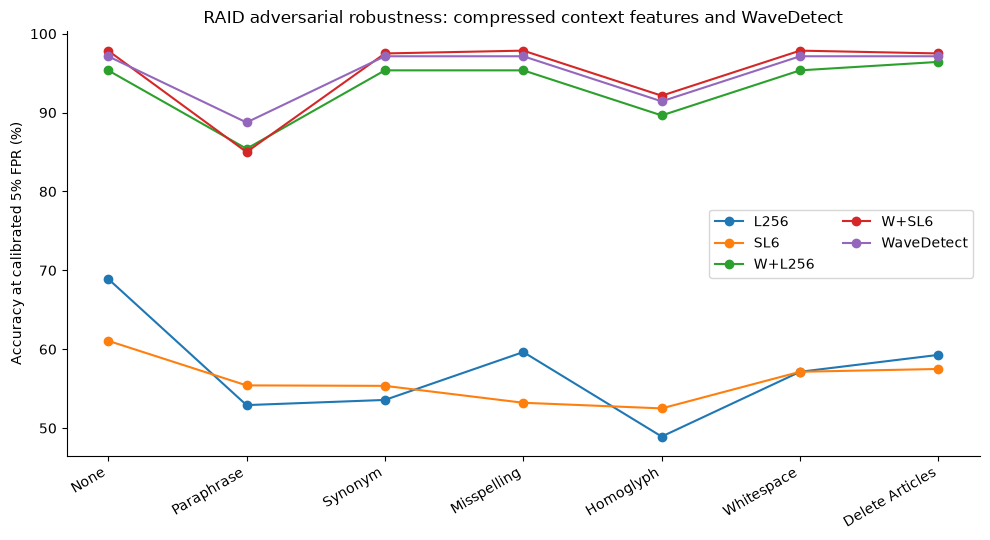

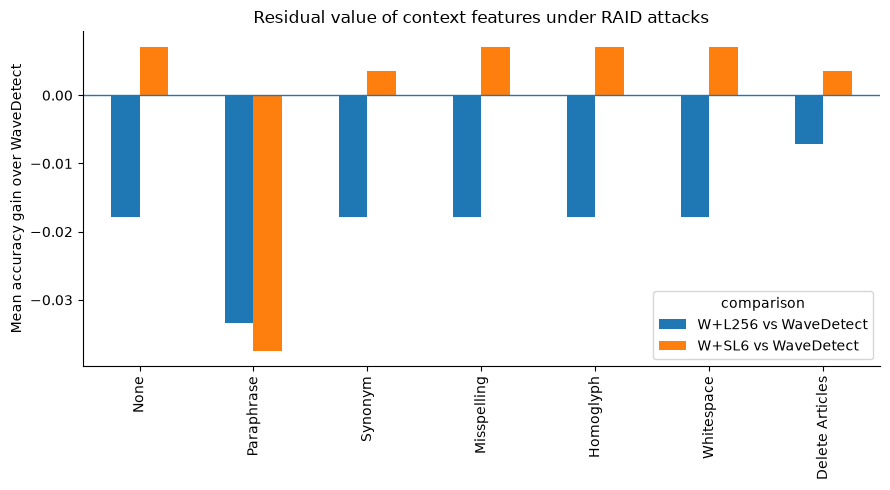

In [13]:
# Our accuracy@5%FPR across the six attacks in RAID Table 6.
plot_cols = [
    "None","Paraphrase","Synonym","Misspelling",
    "Homoglyph","Whitespace","Delete Articles"
]

fig,ax = plt.subplots(figsize=(10,5.5))

x = np.arange(len(plot_cols))

for method,row in our_numeric[plot_cols].iterrows():
    ax.plot(x,row.values,marker="o",label=method)

ax.set_xticks(x)
ax.set_xticklabels(plot_cols,rotation=30,ha="right")
ax.set_ylabel("Accuracy at calibrated 5% FPR (%)")
ax.set_title("RAID adversarial robustness: compressed context features and WaveDetect")
ax.legend(ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_detector_comparison_fpr5.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_detector_comparison_fpr5.png",dpi=200,bbox_inches="tight")
plt.show()

# Gain over WaveDetect.
gp = gains[
    gains["metric"].eq("accuracy_at_fpr5")
    & gains["condition"].isin(["none"]+list(mapping.values()))
].copy()

gp["condition_label"] = gp["condition"].replace({
    "none":"None",
    **{v:k for k,v in mapping.items()}
})

pivot = gp.pivot(
    index="condition_label",
    columns="comparison",
    values="mean_delta",
).reindex(plot_cols)

fig,ax = plt.subplots(figsize=(9,5))
pivot.plot(kind="bar",ax=ax)
ax.axhline(0,linewidth=1)
ax.set_ylabel("Mean accuracy gain over WaveDetect")
ax.set_xlabel("")
ax.set_title("Residual value of context features under RAID attacks")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_wavedetect_context_gain_fpr5.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_wavedetect_context_gain_fpr5.png",dpi=200,bbox_inches="tight")
plt.show()


## 13. Final compact readout

Useful patterns include:

- `L256` or `SL6` exceeding several of the six published RAID detectors on particular attacks;
- WaveDetect exceeding the older published rows;
- `W+L256 > W` or `W+SL6 > W`, especially under attacks where detector performance normally degrades;
- SL6 improving more than \(L_{256}\), which would indicate that attack-sensitive context-shape information is useful beyond a single endpoint.

Negative or heterogeneous results are equally informative. Do not claim exact superiority over RAID's published systems solely from absolute scores because this notebook uses a controlled news-only subset rather than the entire original Table 6 evaluation pool.


In [14]:
print("=== OUR RAID-STYLE TABLE ===")
display(formatted)

print("\n=== SIDE BY SIDE NUMERIC (%) ===")
display(combined.round(1))

print("\n=== WAVEDETECT COMPLEMENTARITY: ACCURACY@5%FPR ===")
display(
    gains[gains["metric"].eq("accuracy_at_fpr5")]
    [["condition","comparison","mean_delta","median_delta","q25","q75","positive","n"]]
)

print("\n=== WAVEDETECT COMPLEMENTARITY: TPR@5%FPR ===")
display(
    gains[gains["metric"].eq("tpr_at_fpr5")]
    [["condition","comparison","mean_delta","median_delta","q25","q75","positive","n"]]
)

print("\n=== ELIGIBILITY ===")
display(eligibility)


=== OUR RAID-STYLE TABLE ===


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
method,,,,,,,
L256,68.9,52.9 (-16.0),53.6 (-15.4),59.6 (-9.3),48.9 (-20.0),57.1 (-11.8),59.3 (-9.6)
SL6,61.1,55.4 (-5.7),55.4 (-5.7),53.2 (-7.9),52.5 (-8.6),57.1 (-3.9),57.5 (-3.6)
W+L256,95.4,85.4 (-9.9),95.4 (+0.0),95.4 (+0.0),89.6 (-5.7),95.4 (+0.0),96.4 (+1.1)
W+SL6,97.9,85.0 (-12.9),97.5 (-0.4),97.9 (+0.0),92.1 (-5.7),97.9 (+0.0),97.5 (-0.4)
WaveDetect,97.1,88.8 (-8.4),97.1 (+0.0),97.1 (+0.0),91.4 (-5.7),97.1 (+0.0),97.1 (+0.0)



=== SIDE BY SIDE NUMERIC (%) ===


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
R-L GPT2,56.7,72.9,79.4,39.5,21.3,40.1,33.2
RADAR,70.9,67.3,67.5,69.5,59.3,66.1,67.9
GLTR,62.6,47.2,31.2,59.8,24.3,45.8,52.1
Binoculars,79.6,80.3,43.5,78.0,37.7,70.1,74.3
GPTZero,66.5,64.0,61.0,65.1,66.2,66.2,61.0
Originality,85.0,96.7,96.5,78.6,9.3,84.9,71.4
L256,68.9,52.9,53.6,59.6,48.9,57.1,59.3
SL6,61.1,55.4,55.4,53.2,52.5,57.1,57.5
W+L256,95.4,85.4,95.4,95.4,89.6,95.4,96.4
W+SL6,97.9,85.0,97.5,97.9,92.1,97.9,97.5



=== WAVEDETECT COMPLEMENTARITY: ACCURACY@5%FPR ===


,condition,comparison,mean_delta,median_delta,q25,q75,positive,n
0,none,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,1,20
1,none,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,3,20
6,alternative_spelling,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,1,20
7,alternative_spelling,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,3,20
12,article_deletion,W+L256 vs WaveDetect,-7.142857e-03,0.0,-0.017857,0.000000,4,20
13,article_deletion,W+SL6 vs WaveDetect,3.571429e-03,0.0,0.000000,0.000000,3,20
18,homoglyph,W+L256 vs WaveDetect,-1.785714e-02,0.0,-0.017857,0.000000,1,20
19,homoglyph,W+SL6 vs WaveDetect,7.142857e-03,0.0,0.000000,0.000000,3,20
24,insert_paragraphs,W+L256 vs WaveDetect,0.000000e+00,0.0,-0.071429,0.071429,6,20
25,insert_paragraphs,W+SL6 vs WaveDetect,-1.428571e-02,0.0,-0.071429,0.000000,3,20



=== WAVEDETECT COMPLEMENTARITY: TPR@5%FPR ===


,condition,comparison,mean_delta,median_delta,q25,q75,positive,n
2,none,W+L256 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
3,none,W+SL6 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
8,alternative_spelling,W+L256 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
9,alternative_spelling,W+SL6 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
14,article_deletion,W+L256 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
15,article_deletion,W+SL6 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
20,homoglyph,W+L256 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
21,homoglyph,W+SL6 vs WaveDetect,0.000000e+00,0.0,0.000000,0.000000,0,20
26,insert_paragraphs,W+L256 vs WaveDetect,3.571429e-02,0.0,0.000000,0.142857,7,20
27,insert_paragraphs,W+SL6 vs WaveDetect,-4.285714e-02,0.0,-0.142857,0.000000,2,20



=== ELIGIBILITY ===


,condition,n_sources
0,none,37
1,alternative_spelling,37
2,article_deletion,36
3,homoglyph,37
4,insert_paragraphs,37
5,number,37
6,paraphrase,32
7,perplexity_misspelling,37
8,synonym,36
9,upper_lower,37
